In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/credit_risk_dataset.csv')

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


EDA


In [4]:
df.shape

(32581, 12)

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [6]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [7]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [8]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [9]:
df.head()
df['loan_status'].unique()

array([1, 0])

Class Imbalance

In [10]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

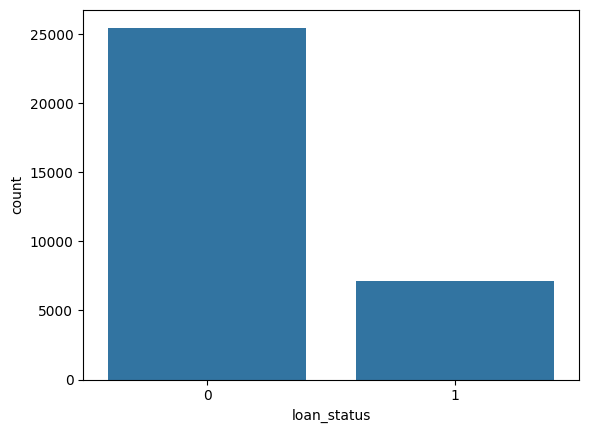

In [11]:
sns.countplot(x='loan_status',data=df)

In [12]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [13]:
numerical_col = df.select_dtypes(include=np.number)

In [14]:
numerical_col.columns

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

In [15]:
categorical_col = df.select_dtypes(exclude=np.number)

In [16]:
categorical_col.columns

Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object')

Outliers

In [17]:
for i in numerical_col :
  print(i)

person_age
person_income
person_emp_length
loan_amnt
loan_int_rate
loan_status
loan_percent_income
cb_person_cred_hist_length


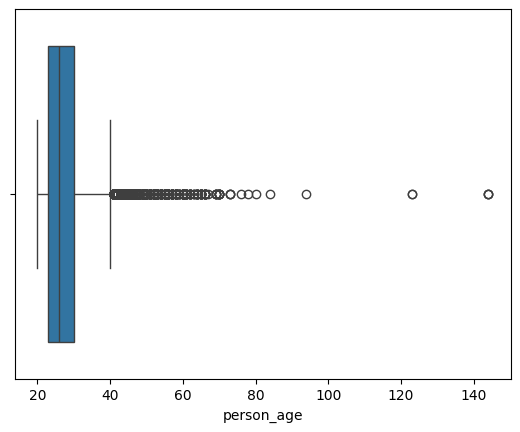

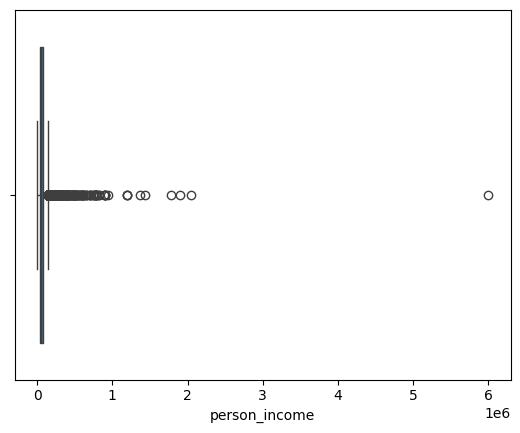

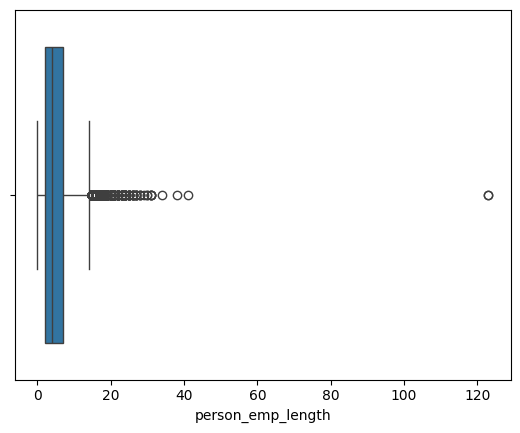

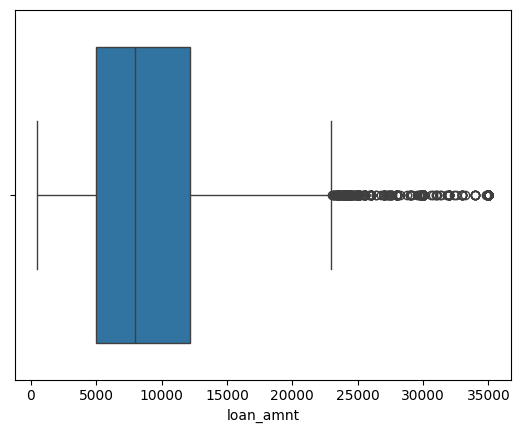

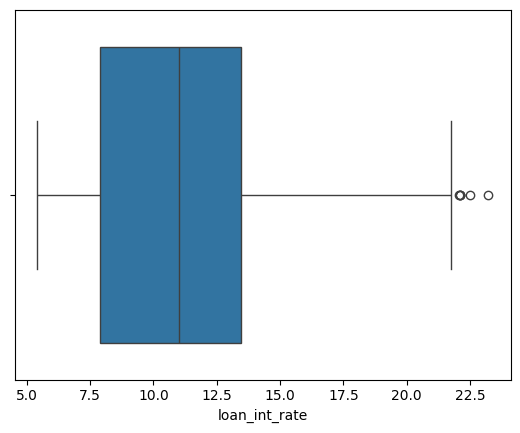

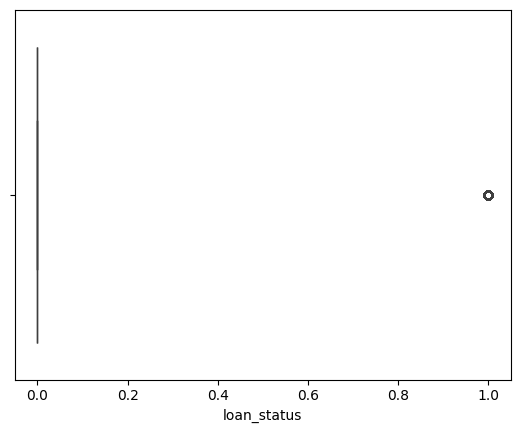

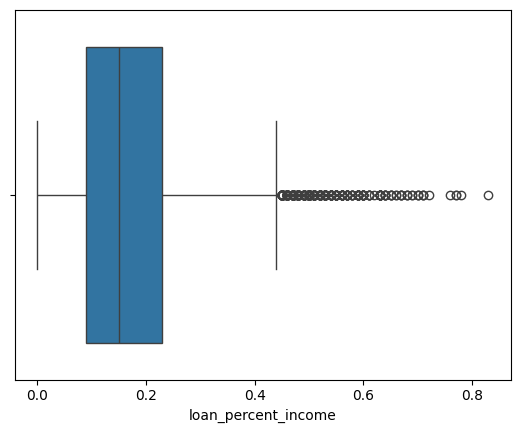

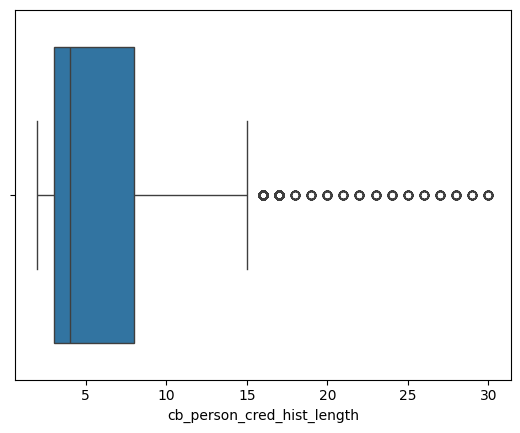

In [18]:
for i in numerical_col :
  sns.boxplot(x=df[i])
  plt.show()


In [19]:
df['person_age']>100

,person_age
0,False
1,False
2,False
3,False
4,False
...,...
32576,False
32577,False
32578,False
32579,False


In [20]:
(df['person_age']>100).sum()

np.int64(5)

In [21]:
(df['person_emp_length']>60).sum()

np.int64(2)

Corelation

<Axes: >

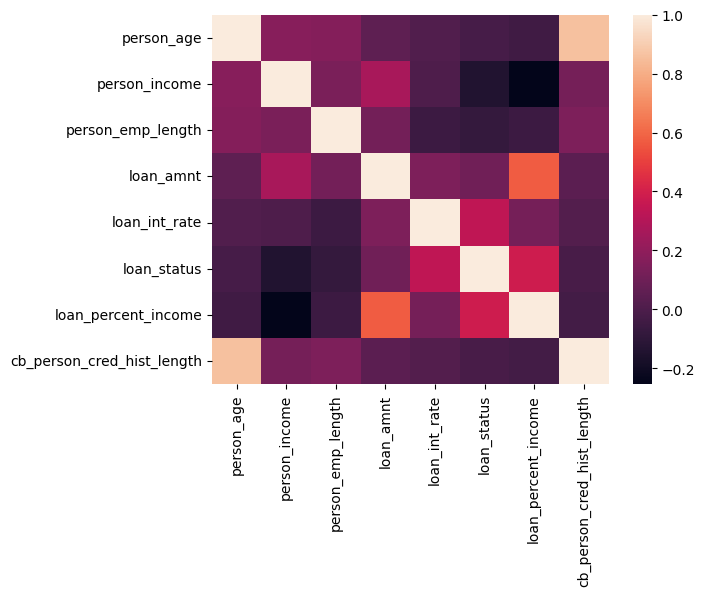

In [22]:
sns.heatmap(df.corr(numeric_only=True))

<Axes: >

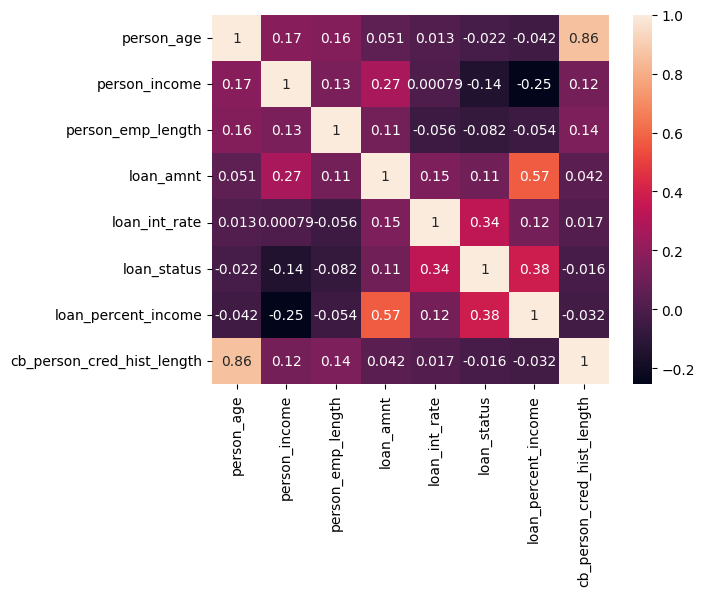

In [23]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

<Axes: >

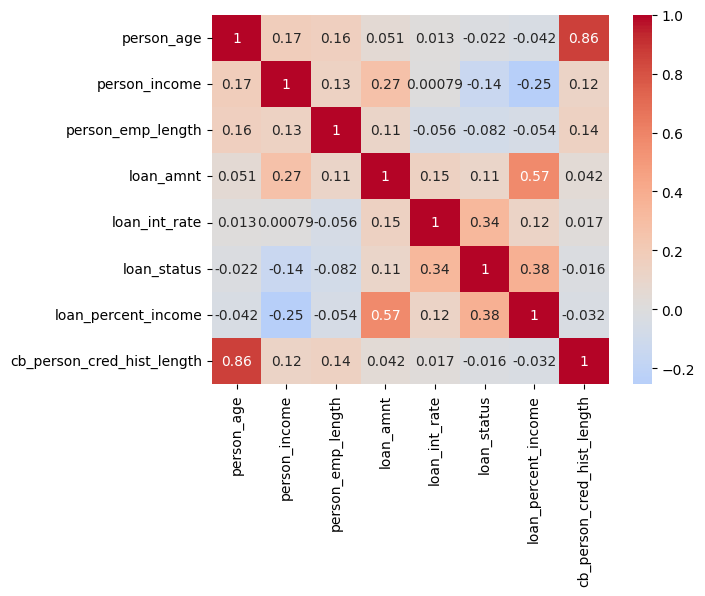

In [24]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)

Data Cleaning or Preprocessing

In [25]:
df_copy=df.copy()

In [26]:
print(f'Orginal Rows, Col : {df_copy.shape}')
print(f'Rows :{df_copy.shape[0]}')

#remove duplicate
print('REMOVE DUPLICATE')

df_copy.drop_duplicates(inplace=True)
print(f'NOW Rows :{df_copy.shape[0]}')


Orginal Rows, Col : (32581, 12)
Rows :32581
REMOVE DUPLICATE
NOW Rows :32416


In [27]:
#impossible age age<18 and age>100
#remove employment <age or extreme outliers(>60)

In [28]:
df_copy= df_copy[df_copy['person_age']>=18]
df_copy= df_copy[df_copy['person_age']<=100]

In [29]:
df_copy=df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]

In [30]:
#neg or zero val

In [31]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


Remove neg income


In [32]:
df_copy = df_copy[df_copy['loan_amnt'] > 0]

Interest rate realistic or not

In [33]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [34]:
print('Loan Interest rate\n{min : 5.42}\n{max: 23.22}')

Loan Interest rate
{min : 5.42}
{max: 23.22}


Feature Scaling train test split

In [35]:
X=df_copy.drop('loan_status',axis=1)
Y=df_copy['loan_status'] #1,0

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [37]:
from pandas.core.arrays import categorical
numerical_col=['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length']


categorical_col=['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file']

**Handle class imbalance**

In [38]:
#class weights
#minority cls e kichu weight dei
#jate kichuta balacne hoi
#logistic e eta inbuilt
#xg boost e nai er jonno alada evaluate kora lage

Class weight logistics e inbuilt thake

In [39]:
#0 = no loan
#1 = yes loan
Y_train.value_counts()

,count
loan_status,
0,19772
1,5445


In [40]:
neg,pos=np.bincount(Y_train)
scale_weight=neg/pos

etai mainly clas weight

In [41]:
scale_weight

np.float64(3.6312213039485766)

**PIPELINE**

**For Logistics**


**1.Impute(null handle)
2.scale numeric
3.impute
4.onehot encode for categorical**

Now baseline model : Logistics


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

In [43]:
preprocessor_lr=ColumnTransformer(
    transformers=[
        ('num',Pipeline( #numerical
            [
              ('imputer',SimpleImputer(strategy='median')),
              ('scaler',StandardScaler())
            ]
        ),numerical_col),

        ('cat',Pipeline( #categorical
            [
              ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
              ('onehot',OneHotEncoder(handle_unknown='ignore'))
            ]
        ),categorical_col)
    ]
)

**Now PIPELINE FOR xG**

No scaling +impute +Onehot encode
(xG nije nije e impute kore fele)

In [44]:
preprocessor_xG=ColumnTransformer(
    transformers=[
        ('num',Pipeline( #numerical
            [
              ('imputer',SimpleImputer(strategy='median')),
                          ]
        ),numerical_col),

        ('cat',Pipeline( #categorical
            [
              ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
              ('onehot',OneHotEncoder(handle_unknown='ignore'))
            ]
        ),categorical_col)
    ]
)

 **Helper Function**

We build one common function to check any model's performance.
It will show accuracy, precision, recall, F1 score, and more.
It will also show a confusion matrix and a precision-recall curve.

To evaluate LR and xG basis on their metrics


In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             precision_recall_curve, roc_auc_score)

In [46]:
def evaluate_model(model_name, model, X_test, Y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:, 1]

  if threshold is not None:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  # Metrics
  accuracy  = accuracy_score(Y_test, y_pred)    # overall performance
  precision = precision_score(Y_test, y_pred)   # when the model says 1, how often is it actually 1
  recall    = recall_score(Y_test, y_pred)      # of the actual 1s, how many the model caught
  f1        = f1_score(Y_test, y_pred)          # harmonic mean of precision and recall
  roc_auc   = roc_auc_score(Y_test, y_pred_prob)

  conf_matrix  = confusion_matrix(Y_test, y_pred)
  class_report = classification_report(Y_test, y_pred)

  print(f"{model_name} Metrics:")
  if threshold is not None:
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy  : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall    : {recall:.2f}")
  print(f"F1        : {f1:.2f}")
  print(f"ROC-AUC   : {roc_auc:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)

  # Confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()

  # Precision-Recall curve
  precisions, recalls, thresholds = precision_recall_curve(Y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

 **Cross validation**

 **1.Model & pipeline
 2.Data : X-Train,Y_train
 3.CV
 4.scoring**

In [47]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate

In [48]:
cv= StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [49]:
scoring={'ROC-AUC':'roc_auc',
         'Accuracy':'accuracy',
         'Precision':'precision',
         'Recall':'recall',
         'F1':'f1'}

In [50]:
#logistics
from sklearn.linear_model import LogisticRegression

In [51]:
Pipeline(
    [
        ('preprocessor', preprocessor_lr),
        ('classifier', LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42))
    ]
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [52]:
lr_cv_pipeline=Pipeline(
    [
        ('preprocessor', preprocessor_lr),
        ('classifier', LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42))
    ]
)

In [53]:
#xG
from xgboost import XGBClassifier

In [54]:
Pipeline(
    [
        ('preprocessor', preprocessor_xG),
        ('classifier', XGBClassifier(n_estimators=100,
                                     max_depth=3,
                                     learning_rate=0.1,
                                     #VVI Scaled weight
                                     scale_pos_weight=scale_weight,
                                     random_state=42))
    ]
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [55]:
xG_cv_pipeline=Pipeline(
    [
        ('preprocessor', preprocessor_xG),
        ('classifier', XGBClassifier(n_estimators=100,
                                     max_depth=3,
                                     learning_rate=0.1,
                                     #VVI Scaled weight
                                     scale_pos_weight=scale_weight,
                                     random_state=42))
    ]
)

In [56]:
for cv_name, pipe in [('Logistic Regression',lr_cv_pipeline),
                      ('xGBoost',xG_cv_pipeline)]:
  print(cv_name)


Logistic Regression
xGBoost


In [57]:
for cv_name, pipe in [('Logistic Regression',lr_cv_pipeline),
                      ('xGBoost',xG_cv_pipeline)]:
  print(cv_name,pipe)


Logistic Regression Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                             

In [58]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xG_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train , Y_train, cv=cv, scoring=scoring, n_jobs=-1)
                      print(cv_name)
                      print(f'Roc-AUC : {cv_results['test_ROC-AUC']}')
                      print()

Logistic Regression
Roc-AUC : [0.87315402 0.86441823 0.86989451 0.87835406 0.8667356 ]

XGBoost
Roc-AUC : [0.92969147 0.91759788 0.92741899 0.92945155 0.92242806]



ProbapProssffewsddsw

In [59]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xG_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train , Y_train, cv=cv, scoring=scoring, n_jobs=-1)
                      print(cv_name)
                      print(f'Roc-AUC : {cv_results['test_ROC-AUC'].mean()}')
                      print(f'Accuracy :{cv_results['test_Accuracy'].mean()}')
                      print(f'Precision :{cv_results['test_Precision'].mean()}')
                      print(f'Recall :{cv_results['test_Recall'].mean()}')
                      print(f'F1 :{cv_results['test_F1'].mean()}')
                      print()

Logistic Regression
Roc-AUC : 0.8705112830525306
Accuracy :0.8115949542892269
Precision :0.5448226008889892
Recall :0.7781450872359963
F1 :0.6408013995933108

XGBoost
Roc-AUC : 0.9253175894641608
Accuracy :0.8896377434790382
Precision :0.7306585323179828
Recall :0.7759412304866851
F1 :0.7523011668977054



In [60]:
cv_results

{'fit_time': array([0.52238441, 0.51046467, 0.4889226 , 0.48975158, 0.29022336]),
 'score_time': array([0.0957408 , 0.09716988, 0.09221268, 0.09446669, 0.0614078 ]),
 'test_ROC-AUC': array([0.92969147, 0.91759788, 0.92741899, 0.92945155, 0.92242806]),
 'test_Accuracy': array([0.89056305, 0.89373513, 0.892326  , 0.88954987, 0.88201467]),
 'test_Precision': array([0.73368146, 0.75530933, 0.73947368, 0.72203673, 0.70279146]),
 'test_Recall': array([0.77410468, 0.75114784, 0.77410468, 0.7943067 , 0.78604224]),
 'test_F1': array([0.75335121, 0.75322284, 0.756393  , 0.7564495 , 0.74208929])}

**BASELINE MODEL FOR LOGISTICS**

In [61]:
baseline_model= Pipeline([
    ('Preprocessor',preprocessor_lr),
    ('Classifier',LogisticRegression(class_weight='balanced'))
])

baseline_model


Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('Classifier', LogisticRegression(class_weight='balanced'))])

In [62]:
baseline_model.fit(X_train,Y_train)

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('Classifier', LogisticRegression(class_weight='balanced'))])

**XGBoost Hyperparameter Tuning**

Now we move to a stronger model, XGBoost.
A model has many settings called hyperparameters.
We search for the best combination of these settings.
We use cross-validation while searching, so the result is reliable.

In [63]:
xg_model=Pipeline(
    [
        ('preprocessor',preprocessor_xG),
        ('classifier',XGBClassifier(learning_rate=0.1,
                                    random_state=42,
                                    scale_pos_weight=scale_weight))
    ]
)


In [64]:
xg_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [65]:
xg_model.fit(X_train,Y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

HYPER PARAMETER

In [66]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
from scipy.stats import randint, uniform

In [67]:
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting


In [68]:
RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79c8d4f0b4d0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79c8d4f0fcb0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79c8d4bd0550>},
                   scoring='average_precision', verbose=1)

In [69]:
random_search=RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)


In [70]:
random_search.fit(X_train,Y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79c8d4f0b4d0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79c8d4f0fcb0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79c8d4bd0550>},
                   scoring='average_precision', verbose=1)

In [71]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.7658170870211186),
 'classifier__gamma': np.float64(1.0420651763949267),
 'classifier__learning_rate': np.float64(0.09667756946456883),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 4,
 'classifier__n_estimators': 277,
 'classifier__subsample': np.float64(0.8919639244662636)}

In [72]:
a=random_search.best_score_
print(f'Best Score After Tuning: {a}')


Best Score After Tuning: 0.9035206120888493


Evaluate Logistics

Baseline logistics model Metrics:
Accuracy  : 0.82
Precision : 0.56
Recall    : 0.79
F1        : 0.65
ROC-AUC   : 0.88

Baseline logistics model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



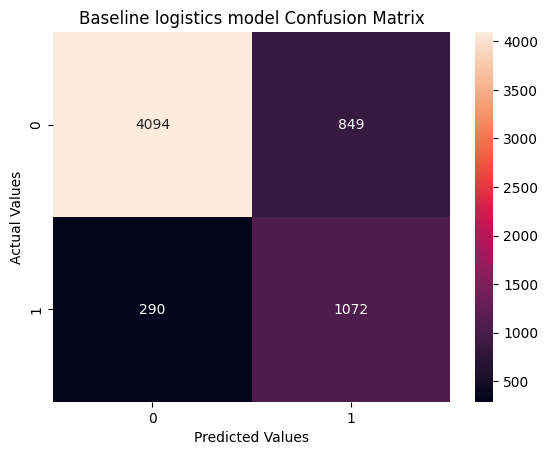

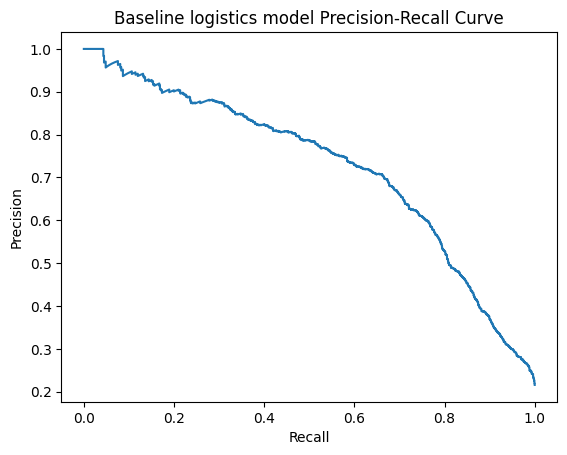

In [73]:
evaluate_model('Baseline logistics model',baseline_model,X_test,Y_test)

XG EVALUATE


XGBoost Metrics:
Accuracy  : 0.92
Precision : 0.82
Recall    : 0.79
F1        : 0.81
ROC-AUC   : 0.95

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



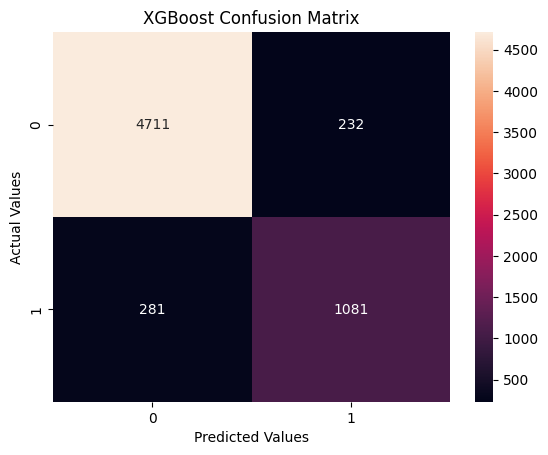

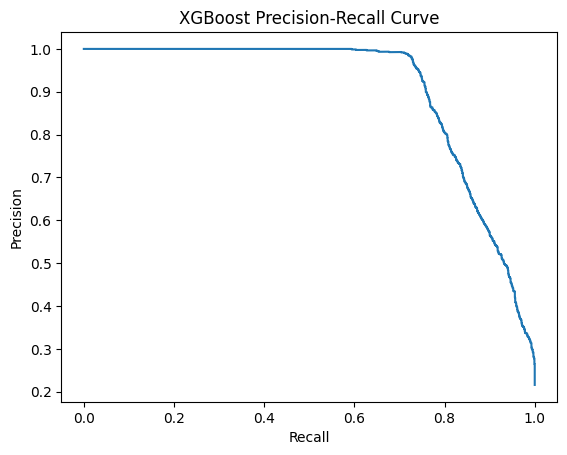

In [74]:
evaluate_model('XGBoost',xg_model,X_test,Y_test)

XG EVALUATE AFTER TUNING

XGboost Metrics:
Accuracy  : 0.92
Precision : 0.83
Recall    : 0.80
F1        : 0.82
ROC-AUC   : 0.95

XGboost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.83      0.80      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.89      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



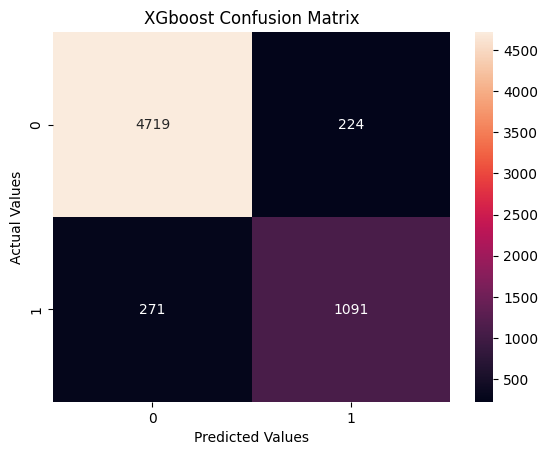

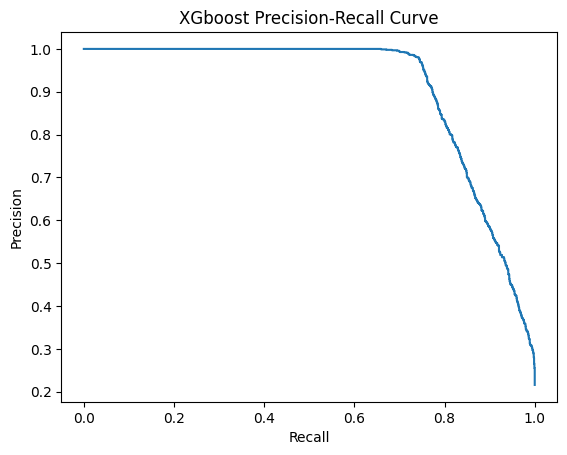

In [75]:
evaluate_model('XGboost',random_search,X_test,Y_test)

Threshold

Optimizing the Classification Threshold
The model gives a probability, not a direct yes or no.
We decide a cut-off point to turn it into a decision.
We check different cut-off points and pick the best one.

Best threshold: 0.731  (F1 = 0.845)
XGBoost (best threshold) Metrics:
Used Threshold : 0.73
Accuracy  : 0.94
Precision : 0.98
Recall    : 0.74
F1        : 0.84
ROC-AUC   : 0.95

XGBoost (best threshold) Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      4943
           1       0.98      0.74      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.96      0.87      0.90      6305
weighted avg       0.94      0.94      0.94      6305



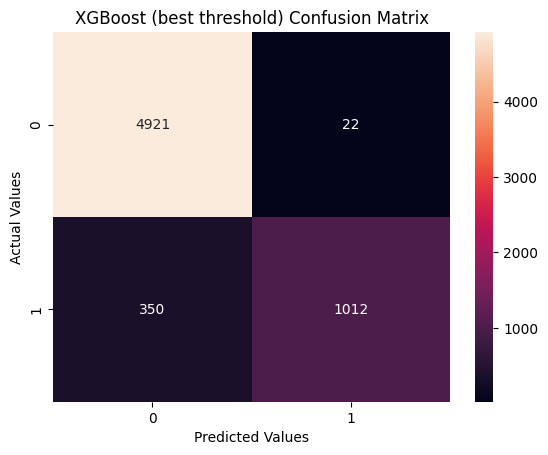

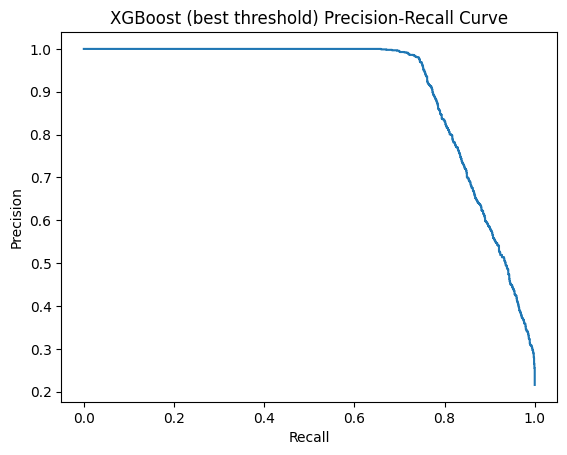

In [76]:
# Use the tuned XGBoost pipeline (already fitted by random_search)
xg_model = random_search.best_estimator_

# Probability of class 1 (default)
prob = xg_model.predict_proba(X_test)[:, 1]

# Precision and recall at every threshold
precisions, recalls, thresholds = precision_recall_curve(Y_test, prob)

# F1 at each threshold
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# Threshold with the highest F1
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]
print(f"Best threshold: {best_threshold:.3f}  (F1 = {f1[best]:.3f})")

# Evaluate with that threshold
evaluate_model("XGBoost (best threshold)", xg_model, X_test, Y_test, best_threshold)

 **Probability Callibration forxG**

1.Calibrated model xGboost

2.Get the probabilities

3.create calibration curves

4.plot

edike xG model soray amra hyper tuning model use korsi abr best model hisabe

In [77]:
#calibrated Model XG boost
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, Y_train)


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.09667756946456883),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=4,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=277,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [78]:
#get the probabilities
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [79]:
uncalibrated

array([0.5188477 , 0.1708781 , 0.99404526, ..., 0.60828733, 0.04426995,
       0.00926782], dtype=float32)

In [80]:
calibrated

array([0.43887605, 0.02942999, 0.95158159, ..., 0.45015851, 0.02248613,
       0.01442531])

In [81]:
#curve
actual_uncal , pred_uncal = calibration_curve(Y_test,uncalibrated,n_bins=10)
actual_cal , pred_cal = calibration_curve(Y_test,calibrated,n_bins=10)

Method by which we can fix poorly calibrated model

1.Plat scaling/sigmoid -> Adjust the probability using sigmoid curve.

(good for small data)


2.Isotonic Regression ->learn a flexible mapping from old prob. ->better prob
(non linear)


3.Temparature Scaling-> Adjust the confidence of neural-network prediction using one temparature

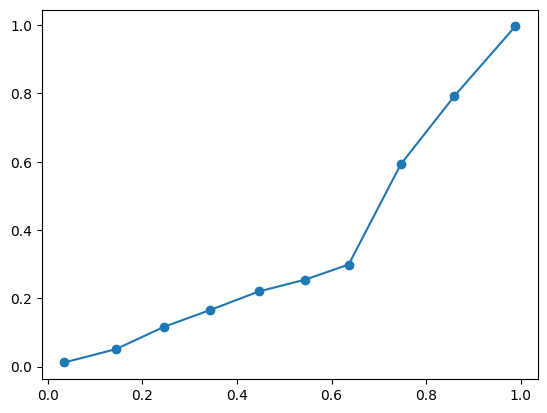

In [82]:
#plot
#uncali
plt.plot(
    pred_uncal,
    actual_uncal,
    'o-',
    label='Uncalibrated'
)

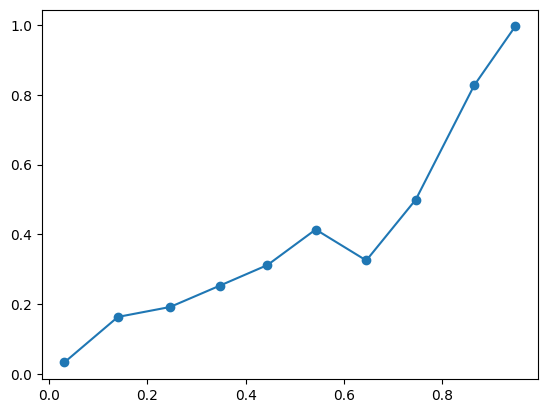

In [83]:
#cali
plt.plot(
    pred_cal,
    actual_cal,
    'o-',
    label='Calibrated'
)

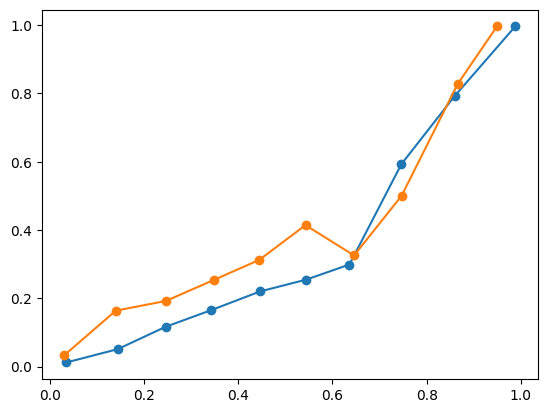

In [84]:
#plot
#uncali
plt.plot(
    pred_uncal,
    actual_uncal,
    'o-',
    label='Uncalibrated'
)
#cali
plt.plot(
    pred_cal,
    actual_cal,
    'o-',
    label='Calibrated'
)

For a straight line

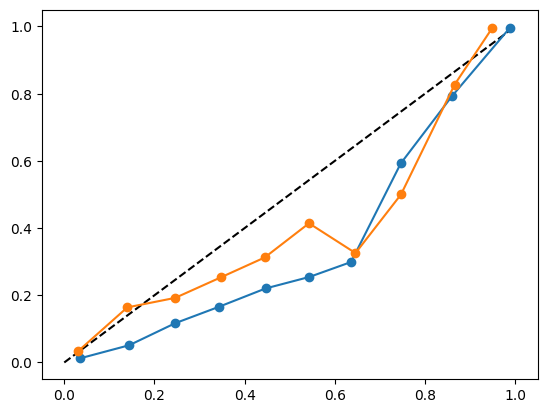

In [85]:
#plot
#uncali
plt.plot([0,1], [0,1], 'k--', label="Prefect")
plt.plot(
    pred_uncal,
    actual_uncal,
    'o-',
    label='Uncalibrated'
)
#cali
plt.plot(
    pred_cal,
    actual_cal,
    'o-',
    label='Calibrated'
)

**SHAP**

SHAP Interpretation — Global & Local
SHAP helps us understand why the model makes a decision.
It is a way of explaining a "black box" model.

2types

local ->for one person
Global ->most important feature in the model

In [86]:
#1.install shap
#2Get the Trained XGBoost classifier model out of the pipeline.
#3. Transform X_test using the same preprocessing used for training.
#4. Get feature names after one-hot enocding , so plots are readable
#5. Convert to a dataframe for cleaner SHAP plots
#6. Create SHAP explainer built for tree-based model
#7. Calculate SHAP values for every row in the test set

!pip install shap

In [87]:
import shap

In [88]:
#Trained xGboost classifier model
#BASEMODEL FOR THIS
xgb_classifier=xg_model.named_steps['classifier']
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.7658170870211186), device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric=None, feature_types=None, feature_weights=None,
              gamma=np.float64(1.0420651763949267), grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=np.float64(0.09667756946456883), max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=4, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=277, n_jobs=None,
              num_parallel_tree=None, ...)

In [89]:
#transform X_test using the same preprocessing used for trauning
#prediction
x_test_transform = xg_model.named_steps['preprocessor'].transform(X_test)

In [90]:
#get the feature name after one hot encoding
#feature that imapct pred
feature_names=xg_model.named_steps['preprocessor'].get_feature_names_out()

In [91]:
#convert dataframe for clear SHAP plots

X_test_df=pd.DataFrame(x_test_transform,columns=feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [92]:
#create SHAP explainer built for tree base model
#SHAP MODEL
#koto percent contribute kon feature
explainer=shap.TreeExplainer(xgb_classifier)

In [93]:
#calculate SHAP for every row in test set
#actual contribute
shap_values=explainer.shap_values(X_test_df)
shap_values

array([[-1.7609726e-01, -1.0130278e-01,  2.6792791e-01, ...,
        -8.8847233e-03, -1.1444524e-02, -9.5428862e-03],
       [-2.8860180e-03, -1.0507358e+00, -5.2672587e-02, ...,
        -1.0901339e-02,  1.1514054e-02,  5.0200876e-03],
       [ 1.7250097e-01,  4.4126801e+00,  9.3488388e-02, ...,
        -9.4411867e-03,  2.5371661e-02,  7.1711247e-03],
       ...,
       [ 5.6051712e-02,  8.3683413e-01,  2.4820086e-01, ...,
        -8.6270031e-03, -1.5849380e-02,  7.4154786e-03],
       [-1.1446976e-01, -1.3841392e+00,  8.4401734e-02, ...,
        -8.6999685e-03, -4.3408759e-02,  4.7955848e-03],
       [-4.9802685e-01, -1.3080144e+00,  2.3448806e-02, ...,
        -8.3958469e-03, -1.7197279e-02,  1.1499278e-03]], dtype=float32)

**Global explanation**

This shows which features matter most overall.
It also shows if a feature increases or decreases risk.

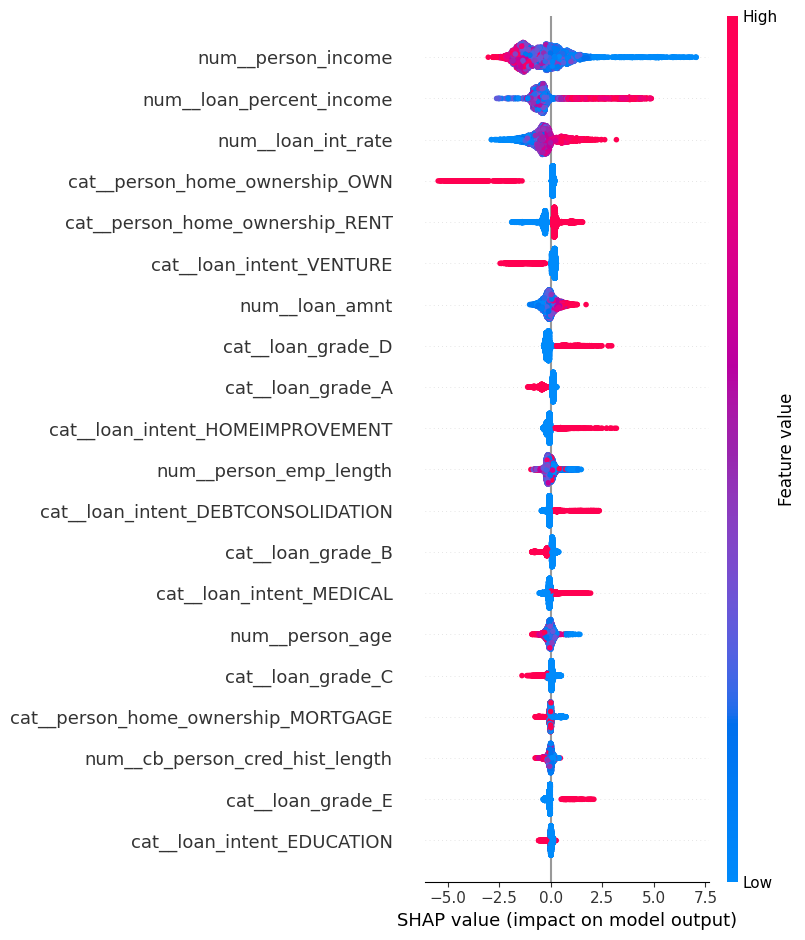

In [94]:
shap.summary_plot(shap_values, X_test_df)

**Local explanation**



This shows why one specific applicant got their score.

just like kn ei customer data so ekhne 5no customer

In [95]:
shap_values[5]

array([ 2.4936963e-02, -1.1687938e+00, -1.1157159e-01, -7.2312714e-03,
       -4.3460065e-01, -3.9314625e-01,  2.4303330e-02, -3.1689417e-03,
       -1.9136825e-04,  9.7506672e-02, -3.2392377e-01, -4.2584181e-02,
        2.2974573e-03, -8.3695680e-02, -1.0691495e-01, -2.6442619e-02,
        2.1330346e-01,  1.2608774e-01, -2.3198377e-01,  4.1293841e-02,
       -1.2461427e-01, -3.8012825e-02, -1.9539524e-02, -9.1726743e-03,
       -1.9578533e-02, -3.6734750e-04], dtype=float32)

In [96]:
X_test_df.iloc[5]

,5
num__person_age,25.00
num__person_income,60000.00
num__person_emp_length,2.00
num__loan_amnt,6900.00
num__loan_int_rate,9.99
num__loan_percent_income,0.12
num__cb_person_cred_hist_length,2.00
cat__person_home_ownership_MORTGAGE,1.00
cat__person_home_ownership_OTHER,0.00
cat__person_home_ownership_OWN,0.00


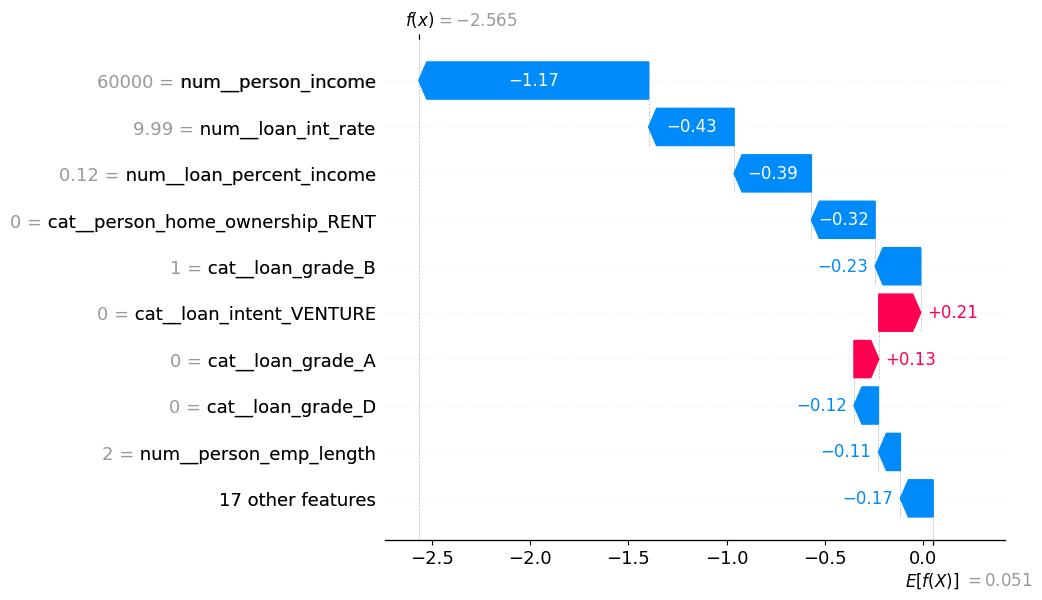

In [97]:
#pick one row

row_index=5

#draw a waterfall for the feature that impact on that rows\
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)


**False Positives & False Negatives**



The model will not be perfect.
False positives are safe people wrongly marked risky.


False negatives are risky people wrongly marked safe.



We study these cases to understand where the model struggles.

In [98]:
#predittion from best model(xGboost from the test set)
Y_pred=random_search.predict(X_test)
Y_pred

array([1, 0, 1, ..., 1, 0, 0])

In [99]:
#dataframe to easily compare
result_df=X_test.copy()
result_df['Actual']=Y_test
result_df['Predicted']=Y_pred
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Actual,Predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


False Pos -> actual 0: model 1

In [100]:
#identify false positive : model precit 1 actual 0
false_positive=result_df[(result_df['Predicted']==1) & (result_df['Actual']==0)]
false_positive

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Actual,Predicted
9417,24,74000,RENT,7.0,EDUCATION,D,8000,15.62,0.11,Y,2,0,1
24046,27,36000,RENT,3.0,PERSONAL,E,10000,17.19,0.28,Y,7,0,1
19523,35,34000,MORTGAGE,4.0,DEBTCONSOLIDATION,A,12800,8.94,0.38,N,7,0,1
15993,24,52000,MORTGAGE,7.0,MEDICAL,C,5000,14.22,0.10,Y,3,0,1
13083,24,88000,MORTGAGE,4.0,MEDICAL,B,6000,9.91,0.07,N,2,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
22809,27,29000,RENT,3.0,MEDICAL,B,7750,11.86,0.27,N,5,0,1
6488,23,44000,RENT,2.0,MEDICAL,C,6000,14.22,0.14,Y,4,0,1
8675,23,30188,RENT,3.0,PERSONAL,C,8000,14.65,0.27,N,2,0,1
8630,25,59650,MORTGAGE,9.0,PERSONAL,C,10000,13.61,0.17,Y,2,0,1


False neg -> actual 1: model 0

In [101]:
#false neg model 0 : actual 1
false_negative=result_df[(result_df['Predicted']==0) & (result_df['Actual']==1)]
false_negative

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Actual,Predicted
8642,23,53950,MORTGAGE,8.0,EDUCATION,E,15000,16.63,0.28,Y,2,1,0
5615,23,39325,MORTGAGE,3.0,EDUCATION,C,2800,12.87,0.07,N,4,1,0
23959,35,62000,MORTGAGE,9.0,HOMEIMPROVEMENT,B,13000,9.25,0.21,N,10,1,0
4305,23,52000,RENT,5.0,PERSONAL,D,4600,14.96,0.09,N,2,1,0
2584,25,29000,RENT,9.0,MEDICAL,A,3000,6.62,0.10,N,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
27976,32,31000,RENT,0.0,EDUCATION,B,5000,11.49,0.16,N,8,1,0
10520,26,52703,MORTGAGE,5.0,MEDICAL,B,4000,11.89,0.06,N,4,1,0
19389,34,30857,RENT,6.0,VENTURE,C,3000,13.06,0.10,N,9,1,0
4105,22,22560,RENT,3.0,PERSONAL,D,4200,15.20,0.19,Y,4,1,0


In [102]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")


False Positive : 224
False Negative : 271


Save the file

In [103]:
import joblib

joblib.dump(calibrated_model,'credit_risk_model.pkl')


['credit_risk_model.pkl']

In [104]:
joblib.dump(best_threshold,'Best_threshold.pkl')

['Best_threshold.pkl']

In [105]:
from sklearn.metrics import precision_recall_curve
import numpy as np

#prob from callibrated model
cali_proba=calibrated_model.predict_proba(X_test)[:,1]

#precision and recall at every threshold
precisions, recalls, thresholds = precision_recall_curve(Y_test, cali_proba)
f1_score=2*(precisions*recalls)/(precisions+recalls+1e-9)
best_threshold=thresholds[np.argmax(f1_score[:-1])]
print(f"New Best threshold: {best_threshold:.3f}  (F1 = {f1_score[np.argmax(f1_score[:-1])]:.3f})")

New Best threshold: 0.695  (F1 = 0.841)


In [106]:
import joblib
from google.colab import files
joblib.dump(calibrated_model, "credit_risk_model.pkl")
joblib.dump(best_threshold, "best_threshold.pkl")

files.download("credit_risk_model.pkl")
files.download("best_threshold.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>